# Morrell's size-specific energy against Bond on the ten surveys: the crusher equation step by step, two fitted variants held out and a negative work index read honestly

**Question:** Does Morrell's size-specific energy for a conventional crusher, set beside Bond's law on the same inputs, explain the motor power of the ten HP500 surveys when each survey is held out, and what does its fitted no-load term say about the ore?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebook 02 of this topic and notebook 02 of topic 05
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- write Morrell's equation for the specific energy of a conventional crusher, say what each of its terms is and where its units come out, and evaluate it on one survey beside Bond's energy for the same reduction;
- turn both laws into a design column, the power per unit of work index, and read what each column does against the measured power of the ten surveys;
- hold each survey out in turn and compare Bond, Morrell and the setting-only line B-lin on the same folds and the same error;
- recognise a fitted work index that has the wrong sign, say why a variant that predicts well with it is not the Morrell model, and name what the surveys cannot decide.

## Setup

Numpy and matplotlib. Everything else, the equations of both laws and the fits, comes from the repository's pipeline.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports bring the survey reader, the backbone builder, the HP500 modules (B-lin, the Morrell fit and the CrusherCal functions), Morrell's equations and the Bond oracle.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, blin, loo, morrell_fit
from pipeline.model.crusher import morrell
from pipeline.oracles import bond_energy_kwh_t, bond_power_kw
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv` and `VERSION`. Morrell's equations come from the GMSG guideline on the Morrell method, Annex B, section B.2.2 (https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf), which is the source the pipeline's module cites; the primary paper is Morrell (2009), https://doi.org/10.1016/j.mineng.2009.01.005.

The cell reads the survey table and builds the backbone, whose P80 of each survey is the product size that both laws need, since the plant measured none.

In [2]:

# The ten surveys, and the backbone's P80 of each (a model output, used below as an input and never as
# a target)
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
bdoc = backbone.build(surveys, version)
rows = bdoc["surveys"]
css = np.array([r["measured"]["css_mm"] for r in rows])
f80 = np.array([r["measured"]["f80_mm"] for r in rows])
tph = np.array([r["measured"]["feed_tph"] for r in rows])
kw = np.array([r["measured"]["power_kw"] for r in rows])
p80 = np.array([r["backbone"]["p80_mm"] for r in rows])
print('surveys: {} | release label: {}'.format(len(surveys), version))
text = (
    'power measured: {:.0f} to {:.0f} kW | feed: {:.0f} to {:.0f} '
    't/h | backbone P80: {:.1f} to {:.1f} mm'
)
print(text.format(kw.min(), kw.max(), tph.min(), tph.max(), p80.min(), p80.max()))


surveys: 10 | release label: 0.12.000
power measured: 187 to 355 kW | feed: 813 to 1639 t/h | backbone P80: 21.2 to 36.6 mm


## Method

**Step 1, Morrell's equation for one survey.** Morrell's method prices a size reduction in a crusher, in the form given by the GMSG guideline (Annex B, section B.2.2, equations B4 and B5), as

$$W_c = S_c\,K_2\,M_{ic}\;4\left(x_2^{f(x_2)} - x_1^{f(x_1)}\right)\ [\mathrm{kWh/t}],\qquad f(x) = -\left(0.295 + \frac{x}{10^{6}}\right),\qquad S_c = \min\left(1,\ 55\,(x_1 x_2)^{-0.2}\right)$$

with $x_1$ and $x_2$ the 80 percent passing sizes of the feed and of the product in micrometres, $K_2$ equal to 1.0 for a crusher in closed circuit with a classifying screen (and 1.19 in open circuit; the pipeline's functions take the closed circuit by default and this notebook keeps it, which changes no result below because the fitted index absorbs any constant factor), and $M_{ic}$ the crusher work index of the ore in kWh/t, measured by the SMC Test. Bond's law ($W = 10\,W_i\,(P_{80}^{-1/2} - F_{80}^{-1/2})$) has the same shape of answer, an energy per tonne, from a different dependence on size. The size term is dimensionless, a micrometre size raised to a small negative power, so $W_c$ carries the unit of $M_{ic}$, and $W_c$ times the throughput in t/h is a power in kW. The cell evaluates every term on survey 1 with $M_{ic} = 1$ kWh/t, taking $x_1$ from the measured f80 and $x_2$ from the backbone's P80, and prints Bond's energy for the same reduction at $W_i = 1$ kWh/t so the two laws can be read per unit of their index.

In [3]:

# Equation B4 of the guideline on survey 1, one term at a time, with M_ic = 1 kWh/t
x1, x2 = f80[0] * 1000, p80[0] * 1000
size = morrell.size_term(x1, x2)
s_c = morrell.hardness_parameter(x1, x2)
w_c = morrell.crusher_specific_energy_kwh_t(x1, x2, 1.0)
w_bond = bond_energy_kwh_t(f80[0], p80[0], 1.0)
print((
    'f(x1) = {:.4f}, f(x2) = {:.4f} with x1 = {:.0f} um and x2 = '
    '{:.0f} um'
).format(morrell.f_exponent(x1), morrell.f_exponent(x2), x1, x2))
print('size term 4 (x2^f(x2) - x1^f(x1)) = {:.5f}'.format(size))
print('hardness parameter S_c = {:.4f}'.format(s_c))
print('W_c = S_c K2 M_ic size term = {:.5f} kWh/t (M_ic = 1)'.format(w_c))
print((
    'Bond energy of the same reduction at Wi = 1 kWh/t = {:.5f} '
    'kWh/t'
).format(w_bond))


f(x1) = -0.3830, f(x2) = -0.3276 with x1 = 88000 um and x2 = 32560 um
size term 4 (x2^f(x2) - x1^f(x1)) = 0.08192
hardness parameter S_c = 0.7062
W_c = S_c K2 M_ic size term = 0.05785 kWh/t (M_ic = 1)
Bond energy of the same reduction at Wi = 1 kWh/t = 0.02171 kWh/t


On survey 1 the feed has an f80 of 88 mm and the backbone's product a P80 of 32.56 mm, a reduction ratio of 2.7. The size term is 0.08192, the hardness parameter $S_c$ is 0.7062 (below 1, so the guideline's correction acts and the energy is scaled down by almost a third), and the energy per unit of work index is 0.05785 kWh/t, against 0.02171 kWh/t for Bond at the same $W_i$ of 1. Morrell's law therefore prices this reduction at 2.7 times Bond's for a unit index, which is not a disagreement: the two indices are different tests on different scales, and each ore carries its own value of each. What matters below is what each law does with the size and the throughput once its index is fitted. The next cell asks whether the guideline's clamp at 1 ever matters on these surveys.

In [4]:

# The hardness parameter of every survey, to see whether the guideline's clamp at 1 ever acts
s_all = [morrell.hardness_parameter(a * 1000, b * 1000) for a, b in zip(f80, p80)]
print('S_c over the ten surveys: {:.3f} to {:.3f}'.format(min(s_all), max(s_all)))


S_c over the ten surveys: 0.629 to 0.872


$S_c$ runs from 0.629 to 0.872 over the ten surveys: the correction acts on all of them and the clamp never does, so the rule `min(1, ...)` of the guideline is not what separates one survey from another. $S_c$ falls as the sizes grow, so it shaves the energy most for the coarsest reductions.

**Step 2, the design column.** The pipeline writes both laws as a power linear in one unknown. For a survey with measured f80, backbone P80 and measured feed rate $Q$, the power predicted by Morrell is $M_{ic}\,g$ with $g = W_c(M_{ic} = 1)\,Q$ in kW per kWh/t (`morrell_fit.design_column`), and the power predicted by Bond is $W_i\,g_B$ with $g_B = W(W_i = 1)\,Q$. Putting the measured throughput in the column is a choice of the model, the plant's feed rate being an input of the power question; the P80 is the backbone's and is an input too, never a target, because the plant measured none. The cell builds both columns for the ten surveys and prints them with the setting and the measured power.

In [5]:

# The design column of each survey: kW per kWh/t of work index, for Morrell and for Bond, at the
# measured t/h
g_morrell = morrell_fit.design_column(f80, p80, tph)
g_bond = np.array([bond_power_kw(q, a, b, 1.0) for q, a, b in zip(tph, f80, p80)])
print((
    'survey  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW measured  g '
    'Morrell  g Bond'
))
for k in range(len(kw)):
    print(f"{k + 1:6d} {css[k]:9.0f} {f80[k]:9.0f} {p80[k]:9.2f} {tph[k]:6.0f}", end=" ")
    print(f"{kw[k]:11.0f} {g_morrell[k]:10.1f} {g_bond[k]:7.1f}")


survey  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW measured  g Morrell  g Bond
     1        54        88     32.56   1639         209       94.8    35.6
     2        54        84     31.36   1267         212       74.5    27.8
     3        48        47     21.23   1240         262       76.0    27.9
     4        48        88     30.80   1034         349       64.1    24.1
     5        48        62     24.54   1124         325       72.4    26.6
     6        40        79     26.54    813         355       56.4    21.0
     7        38       140     36.60   1050         306       65.7    26.8
     8        44       123     35.69   1138         325       70.2    27.8
     9        40        81     26.97    820         350       56.7    21.1
    10        55        81     30.72   1334         187       78.6    29.2


The Morrell column runs from 56.4 to 94.8 kW per kWh/t and the Bond column from 21.0 to 35.6; the ratio of the two lies between 2.45 and 2.73, so over these surveys the two laws are close to proportional, within about 10 percent of one scale factor: whatever one does with the data, the other does with that factor and a mild tilt. Measured power spans 187 to 355 kW. Each unit of work index buys more power in the survey with the large throughput, so the question for both laws is whether the columns rank the surveys as the motor does. The cell counts that with the correlation, and adds the setting for reference.

In [6]:

# Correlation of each design column, and of the setting, with the measured power
r_morrell = np.corrcoef(g_morrell, kw)[0, 1]
r_bond = np.corrcoef(g_bond, kw)[0, 1]
r_css = np.corrcoef(css, kw)[0, 1]
print((
    'correlation with measured kW: Morrell column {:.2f}, Bond '
    'column {:.2f}, setting CSS {:.2f}'
).format(r_morrell, r_bond, r_css))


correlation with measured kW: Morrell column -0.81, Bond column -0.78, setting CSS -0.82


The figure plots the measured power against each column, one point per survey, numbered as in the table.

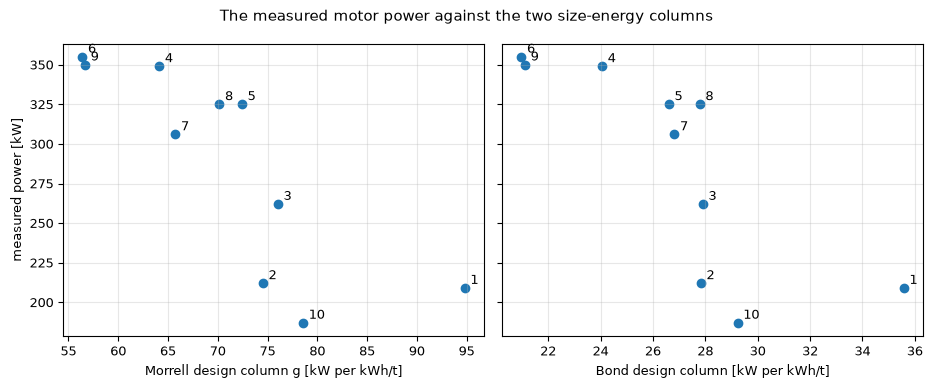

In [7]:

# Measured power against each design column, one point per survey
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
panels = (
    (g_morrell, 'Morrell design column g [kW per kWh/t]'),
    (g_bond, 'Bond design column [kW per kWh/t]'),
)
for ax, (column, xlabel) in zip(axes, panels):
    ax.scatter(column, kw, color="tab:blue")
    for k in range(len(kw)):
        ax.annotate(str(k + 1), (column[k], kw[k]), textcoords="offset points", xytext=(4, 3))
    ax.set_xlabel(xlabel)
axes[0].set_ylabel('measured power [kW]')
fig.suptitle('The measured motor power against the two size-energy columns')
fig.tight_layout()
plt.show()


Both columns correlate negatively with the measured power (-0.81 for Morrell, -0.78 for Bond), about as strongly as the setting itself (-0.82). Two things follow. A law whose prediction is proportional to its column, which is every model with a work index and no intercept, predicts the highest power where the column is highest, and the figure shows that is where the motor draws least: the surveys with the large throughput and the coarse setting. And the sign is not an accident of Morrell's constants, since Bond's column does the same; it comes from what the plant did: the surveys with the finer setting have the lower throughput and the higher measured power. The figure does not show that Morrell's equation is wrong for crushers in general; it shows that on this data the product of an energy per tonne and the measured throughput points the wrong way: the motor drew the least power where the feed rate was the highest.

## Comparison

Morrell's index is not published for the Minas Rio itabirite, so it has to be fitted, and so does Bond's (the engine ships a blend value, $W_i$ = 9 kWh/t, from the paper's bands). The comparison uses the product's own protocol, strict leave-one-survey-out: each model is refit on nine surveys, with `morrell_fit.fit_through_origin` for the index alone and `morrell_fit.fit_with_no_load` for the index plus a no-load power (the guideline defines the net power as the motor power less the no-load, so a measured motor power carries it), and predicts the tenth. Six models run on the same folds: Bond at the engine's fixed index with no fit, Bond refit, Bond with a no-load term, Morrell refit, Morrell with a no-load term, and, as the bar, B-lin, a straight line of the power on the closed-side setting refit on the nine surveys of each fold (`blin.fit_line`). The error is the mean absolute percentage error of the held-out power.

In [8]:

# Leave-one-survey-out: each model is refit on nine surveys and predicts the tenth
names = ("bond_nominal", "bond", "bond_noload", "morrell", "morrell_noload", "b_lin")
n = len(kw)
held = {name: np.zeros(n) for name in names}
fitted = []
for i in range(n):
    train = np.array([j for j in range(n) if j != i])
    held["bond_nominal"][i] = 9.0 * g_bond[i]
    held["bond"][i] = morrell_fit.fit_through_origin(g_bond, kw, train) * g_bond[i]
    m_b, p_b = morrell_fit.fit_with_no_load(g_bond, kw, train)
    held["bond_noload"][i] = m_b * g_bond[i] + p_b
    held["morrell"][i] = morrell_fit.fit_through_origin(g_morrell, kw, train) * g_morrell[i]
    m_m, p_m = morrell_fit.fit_with_no_load(g_morrell, kw, train)
    held["morrell_noload"][i] = m_m * g_morrell[i] + p_m
    fitted.append((m_m, p_m))
    held["b_lin"][i] = blin.predict_line(blin.fit_line(css, kw, train), css[i])


The cell below prints the held-out error of the six models, the mean absolute percentage error and the root mean square error in kW, so that the ranking can be read in one place.

In [9]:

# Held-out error of each model on the power
label = {
    "bond_nominal": "Bond, the engine's Wi = 9 kWh/t, no fit",
    "bond": 'Bond, Wi refit through the origin',
    "bond_noload": 'Bond, Wi and a no-load term',
    "morrell": 'Morrell, M_ic refit through the origin',
    "morrell_noload": 'Morrell, M_ic and a no-load term',
    "b_lin": 'B-lin, a line on the setting',
}
print('model                                     MAPE [%]  RMSE [kW]')
for name in names:
    print(f"{label[name]:42s} {loo.mape(kw, held[name]):8.2f} {loo.rmse(kw, held[name]):10.2f}")


model                                     MAPE [%]  RMSE [kW]
Bond, the engine's Wi = 9 kWh/t, no fit       31.72     103.73
Bond, Wi refit through the origin             36.44     109.72
Bond, Wi and a no-load term                   16.27      47.28
Morrell, M_ic refit through the origin        38.08     111.67
Morrell, M_ic and a no-load term              15.21      46.53
B-lin, a line on the setting                  12.78      44.56


Held out, the engine's fixed Bond index gives 31.72 percent, Bond refit 36.44, Morrell refit 38.08, and the two variants with a no-load term 16.27 for Bond and 15.21 for Morrell, against 12.78 for B-lin. The through-origin Morrell is the worst of the lot, and no better than Bond refit in the same form (36.44): on these surveys the published size-specific energy does not beat the older law, it only restates it. Adding a no-load term turns 38.08 into 15.21, which is a large gain, and brings Morrell to within 2.44 points of a line that uses nothing but the setting. Bond with the same extra term reaches 16.27, only 1.05 points behind, so the gain comes from the intercept and not from Morrell's size law. The next cell checks that these numbers are the pipeline's own.

In [10]:

# One reproduction check: the pipeline's own held-out document, built live, must give the same MAPE
strict = loo.build(bdoc, version)["loo"]["kW"]["strict"]
ours = (loo.mape(kw, held["morrell"]), loo.mape(kw, held["morrell_noload"]), loo.mape(kw, held["b_lin"]))
theirs = (strict["Morrell"]["mape_pct"], strict["Morrell_noload"]["mape_pct"], strict["B_lin"]["mape_pct"])
for tag, a, b in zip(("Morrell", "Morrell_noload", "B_lin"), ours, theirs):
    print('{:32s} here {:6.2f} %, pipeline {:6.2f} %'.format(tag, a, b))
print('all three agree: {}'.format(np.allclose(ours, theirs, atol=0.005)))


Morrell                          here  38.08 %, pipeline  38.08 %
Morrell_noload                   here  15.21 %, pipeline  15.21 %
B_lin                            here  12.78 %, pipeline  12.78 %
all three agree: True


The three values agree to the second decimal, so the fold loop of this notebook is the loop of the product's validation document; the other three models have no counterpart in that document and are what this notebook adds. The figure draws the measured power against the held-out prediction of Bond refit, Morrell and Morrell with a no-load term, and B-lin, with the identity line.

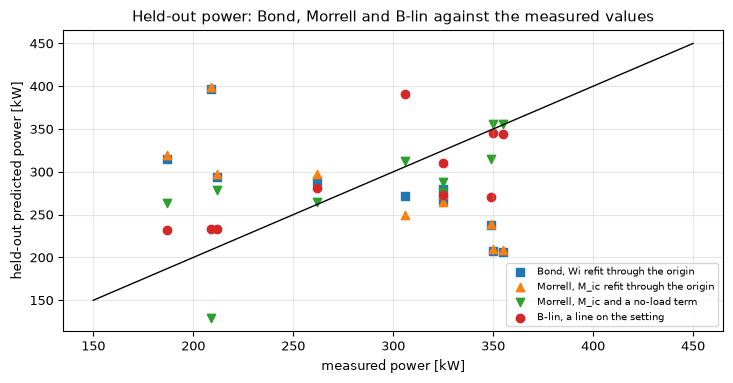

In [11]:

# Measured power against the held-out prediction of four models
fig, ax = plt.subplots()
for name, marker in (("bond", "s"), ("morrell", "^"), ("morrell_noload", "v"), ("b_lin", "o")):
    ax.scatter(kw, held[name], marker=marker, label=label[name])
ax.plot([150, 450], [150, 450], color="black", lw=1)
ax.set_xlabel('measured power [kW]')
ax.set_ylabel('held-out predicted power [kW]')
ax.set_title((
    'Held-out power: Bond, Morrell and B-lin against the measured '
    'values'
))
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Points on the identity line are perfect predictions. The through-origin models, Bond refit and Morrell, sit in a cloud that falls as the measured power rises, far above the line at the low measured powers and below it at the high ones, the shape of a model whose slope has the wrong sign being forced through the origin; their held-out RMSE is 109.7 and 111.7 kW on a measured spread of 187 to 355 kW. Morrell with a no-load term and B-lin lie closer to the line, with a scatter of 46.5 and 44.6 kW. The figure does not say why the no-load variant works; the band below and then the coefficients do.

The scatter can be put in one number the way CrusherCal does for its own model: the 80 percent predictive band of a held-out model is its prediction plus or minus 1.2816 times the standard deviation of its held-out residuals (`loo.predictive_band`). The cell prints that band for the four models that the figure shows.

In [12]:

# The 80 percent predictive band that each model's held-out residuals would earn, with CrusherCal's
# own function
print((
    'model                                     sigma [kW]  '
    'half-width [kW]'
))
for name in ("bond", "morrell", "morrell_noload", "b_lin"):
    band = loo.predictive_band(kw - held[name])
    print(f"{label[name]:42s} {band['sigma']:9.1f} {band['halfwidth']:20.1f}")


model                                     sigma [kW]  half-width [kW]
Bond, Wi refit through the origin              115.0                147.4
Morrell, M_ic refit through the origin         117.0                150.0
Morrell, M_ic and a no-load term                48.9                 62.7
B-lin, a line on the setting                    46.8                 60.0


The 80 percent band of Bond refit is plus or minus 147 kW and that of Morrell plus or minus 150 kW, wider than the whole measured range of 168 kW (from 187 to 355): a band that wide says nothing about which survey draws more. Morrell with a no-load term gives plus or minus 63 kW and B-lin plus or minus 60 kW, about a third of that range on each side. The band is the cost of the prediction in kW, and it reproduces the ordering of the MAPE: the through-origin laws carry no information about the power of a held-out survey, and the no-load line does only because its column carries the measured throughput, as the cells below show.

**The negative work index.** A work index is a measured property of a rock, a positive energy. The variant with a no-load term fits two numbers per fold, and the cell prints them: the index $M_{ic}$ the fold chose, the no-load power, and whether the index is positive. The pipeline flags the same thing in its document as `noload_variant_m_ic_positive`.

In [13]:

# The coefficients each fold fitted for Morrell with a no-load term
print('held-out survey   M_ic [kWh/t]   no-load [kW]   M_ic positive')
for k, (m_ic, no_load) in enumerate(fitted):
    print(f"{k + 1:16d} {m_ic:14.2f} {no_load:14.1f} {m_ic > 0!s:>14}")
print('smallest measured power in the ten surveys: {:.0f} kW'.format(kw.min()))


held-out survey   M_ic [kWh/t]   no-load [kW]   M_ic positive
               1          -6.29          726.7          False
               2          -4.46          611.0          False
               3          -4.65          618.4          False
               4          -4.46          601.4          False
               5          -4.73          618.5          False
               6          -4.68          620.2          False
               7          -4.70          622.0          False
               8          -4.64          613.5          False
               9          -4.74          625.2          False
              10          -4.16          590.7          False
smallest measured power in the ten surveys: 187 kW


The index is negative in all ten folds, from -6.3 to -4.2 kWh/t, and the fitted no-load power is 591 to 727 kW, which is 3.2 to 3.9 times the smallest power the motor ever drew, 187 kW, in a crusher whose idle draw cannot exceed what it draws loaded. Neither number is physical. A negative $M_{ic}$ means that the energy the law assigns to the survey is subtracted: the fit has found that power falls as the Morrell column rises (the correlation of the figure above) and has solved for a negative slope and an intercept large enough to bring the line back to the data. The prediction is then a straight line with a negative slope in a column that rises with both the throughput and the setting, so it can be a good predictor without the equation being used as an energy law at all. The cell measures what the column and the prediction follow, and scores B-lin's own held-out line with the throughput in place of the setting.

In [14]:

# What the no-load variant follows: the design column and the held-out prediction against the throughput,
# the setting and B-lin
pairs = (
    ('correlation of the Morrell column g with the throughput', g_morrell, tph),
    ('correlation of the Morrell column g with the setting CSS', g_morrell, css),
    ('correlation of the throughput with the setting CSS', tph, css),
    ('correlation of the throughput with the measured kW', tph, kw),
    ('correlation of the no-load prediction with the throughput', held["morrell_noload"], tph),
    ('correlation of the no-load prediction with the setting CSS', held["morrell_noload"], css),
    ("correlation of the no-load prediction with B-lin's prediction", held["morrell_noload"], held["b_lin"]),
)
for tag, first, second in pairs:
    print(f"{tag:62s} {np.corrcoef(first, second)[0, 1]:+.2f}")
# B-lin's own held-out line, fitted on the throughput in place of the setting
held_tph = np.zeros(n)
for i in range(n):
    train = np.delete(np.arange(n), i)
    held_tph[i] = blin.predict_line(blin.fit_line(tph, kw, train), tph[i])
print(f"held-out line of the power on the throughput: MAPE {loo.mape(kw, held_tph):.2f} %, "
      f"RMSE {loo.rmse(kw, held_tph):.2f} kW")


correlation of the Morrell column g with the throughput        +0.99
correlation of the Morrell column g with the setting CSS       +0.79
correlation of the throughput with the setting CSS             +0.81
correlation of the throughput with the measured kW             -0.85
correlation of the no-load prediction with the throughput      -0.96
correlation of the no-load prediction with the setting CSS     -0.71
correlation of the no-load prediction with B-lin's prediction  +0.66
held-out line of the power on the throughput: MAPE 14.37 %, RMSE 42.41 kW


The design column is the throughput in all but name: it correlates +0.99 with the measured t/h and +0.79 with the setting, and over these ten surveys the throughput and the setting themselves move together (+0.81). The held-out values of the no-load variant follow the throughput (-0.96) more closely than the setting (-0.71) or B-lin (+0.66). A plain held-out line of the power on the throughput, the least-squares fit of B-lin with the t/h column in place of the setting, scores 14.37 percent and 42.41 kW, better than Morrell with a no-load term (15.21 percent and 46.53 kW): the variant is a line on the measured feed rate, and Morrell's energy law adds only the small tilt between its column and the throughput, which costs it accuracy. Which of the two the motor follows, these surveys cannot say: the throughput correlates -0.85 with the measured power and the setting -0.82, and the two are tied to each other. It is a descriptive line and the product reports it as one. The figure draws the two lines fitted on all ten surveys in the plane of the column, to see what the fit does.

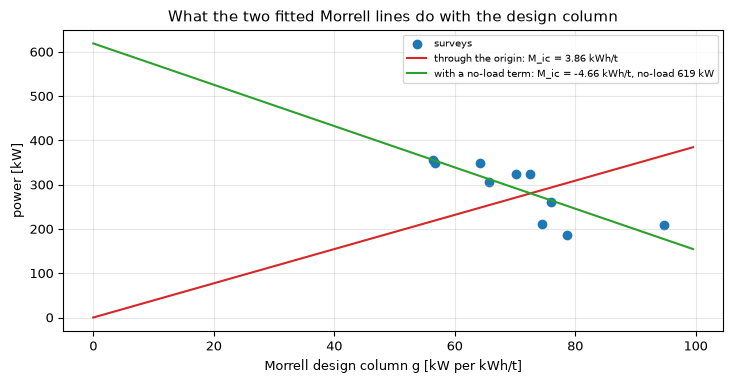

In [15]:

# The two Morrell lines fitted on all ten surveys, in the plane of the design column
every = np.arange(n)
m_all = morrell_fit.fit_through_origin(g_morrell, kw, every)
m_nl, p_nl = morrell_fit.fit_with_no_load(g_morrell, kw, every)
x = np.linspace(0, g_morrell.max() * 1.05, 50)
fig, ax = plt.subplots()
ax.scatter(g_morrell, kw, color="tab:blue", label='surveys')
label_o = 'through the origin: M_ic = {:.2f} kWh/t'.format(m_all)
label_n = 'with a no-load term: M_ic = {:.2f} kWh/t, no-load {:.0f} kW'.format(m_nl, p_nl)
ax.plot(x, m_all * x, color="tab:red", label=label_o)
ax.plot(x, m_nl * x + p_nl, color="tab:green", label=label_n)
ax.set_xlabel('Morrell design column g [kW per kWh/t]')
ax.set_ylabel('power [kW]')
ax.set_title('What the two fitted Morrell lines do with the design column')
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Fitted on all ten surveys, the through-origin line has an index of 3.86 kWh/t and runs up through the middle of a cloud that goes down; the line with a no-load term has an index of -4.66 kWh/t and a no-load power of 619 kW, falls across the cloud and is the better description of the points. The figure shows why the positive-index model fails and the negative-index model does not: the data want a downward slope and the equation, with a work index that is a positive energy, can only give an upward one. It does not show that a different feed definition, or Morrell's index measured by the SMC Test on the real ore, would not give a positive fit; the ten surveys contain no such measurement.

## Results

**Answer:** no. With each survey held out, Morrell's size-specific energy does not explain the motor power of the ten HP500 surveys better than Bond's law. Refit through the origin, the index alone on a motor power that still includes the no-load draw, Morrell has a held-out error of 38.08 percent, against 36.44 for Bond refit in the same form, 31.72 for Bond at the engine's fixed index and 12.78 for the setting-only line B-lin. Both laws fail for one reason the notebook measured: their design columns correlate -0.81 (Morrell) and -0.78 (Bond) with the measured power, and a model proportional to its column predicts the most power where the motor draws the least. The variant with a no-load term reaches 15.21 percent only by fitting a negative work index in all ten folds, from -6.3 to -4.2 kWh/t, and a no-load power of 591 to 727 kW, 3.2 to 3.9 times the smallest measured draw of 187 kW. Its column correlates +0.99 with the throughput, its held-out values -0.96, and a plain held-out line on the throughput does better, 14.37 percent: it is a descriptive line on the measured feed rate, not Morrell's model. Its fitted no-load term says nothing about the ore: it is the intercept of that line, not an idle draw of the crusher, and the work index it comes with is negative. What the ten surveys cannot decide is whether the throughput or the setting governs the motor, since the two move together (+0.81), and whether Morrell's equation, with an index measured by the SMC Test on this ore and a measured product size, would do better: no index was measured and the product size used is the backbone's.

## Summary

Morrell's crusher equation is a size-reduction energy priced per tonne, with a hardness correction and a work index that the ore must supply. Run on the HP500 surveys with the index fitted, it behaves like Bond's law rescaled and inherits its failure on this machine: the motor drew the least power where the feed rate was the highest, and a law that multiplies an energy per tonne by the throughput predicts the opposite direction. The only variant that predicts well does so with a negative work index and an impossible no-load power, which makes it a line on the measured throughput, and the product reports it that way; whether the throughput or the setting governs the motor, these surveys, in which the two move together, cannot say. The method that does use the setting, and the Bayesian calibration that puts a discrepancy around the engine, are the subject of the topic that follows.

## References

- Morrell, S. (2009), Predicting the overall specific energy requirement of crushing, high pressure grinding roll and tumbling mill circuits, Minerals Engineering 22(6), 544-549. https://doi.org/10.1016/j.mineng.2009.01.005
- GMSG, Morrell Method for Determining Comminution Circuit Specific Energy and Assessing Energy Utilization Efficiency of Existing Circuits, Annex B, section B.2.2 (equations B4 and B5). https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193. https://onemine.org/documents/the-third-theory-of-comminution
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919